<div style="background:linear-gradient(135deg,#123524 0%,#1f5a45 45%,#2B5A82 100%);color:#fff;padding:40px 36px;border-radius:16px;font-family:system-ui,-apple-system,'Segoe UI',sans-serif">
  <div style="font-size:12px;letter-spacing:.16em;opacity:.75;text-transform:uppercase">43008 Reinforcement Learning &middot; Assignment 3 &middot; Team LMF</div>
  <div style="font-size:46px;font-weight:800;line-height:1.05;margin:12px 0 6px">Experiment: A2C</div>
  <div style="font-size:19px;opacity:.92">Advantage Actor-Critic on AgriFlight-RL, crop-row flight stabilisation</div>
  <div style="height:1px;background:rgba(255,255,255,.28);margin:24px 0 18px"></div>
  <div style="display:flex;flex-wrap:wrap;gap:36px">
    <div><div style="font-size:11px;letter-spacing:.12em;opacity:.7;text-transform:uppercase">Student</div><div style="font-size:20px;font-weight:600">Panzhao Li</div></div>
    <div><div style="font-size:11px;letter-spacing:.12em;opacity:.7;text-transform:uppercase">Student ID</div><div style="font-size:20px;font-weight:600">25399217</div></div>
    <div><div style="font-size:11px;letter-spacing:.12em;opacity:.7;text-transform:uppercase">Environment</div><div style="font-size:20px;font-weight:600">AgroDrone-v0 &middot; MuJoCo Skydio X2</div></div>
  </div>
</div>

### Contents

1. [Introduction](#intro): question, hypothesis, success criterion
2. [Setup](#setup): environment, config, seeds, shared helpers
3. [Theory](#theory): the algorithm in your own words
4. [Implementation](#implementation): the code
5. [Training](#training): run, curve, stability
6. [Evaluation](#evaluation): held-out seeds, baselines, difficulty levels
7. [Results](#results): table and plots
8. [Discussion](#discussion): what worked, what did not, limits
9. [Contribution and reproducibility](#contribution): who did what, versions, references

<div style="border-left:4px solid rgb(140,90,43);background:rgba(140,90,43,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Template status (delete this box before submitting).</b> <code>Run all</code> works today and produces the baseline numbers. Cells marked <i>Write here</i> or <code>TODO</code> are yours. Do not edit the cells labelled <i>Shared, identical in all three notebooks</i>: the comparison is only fair if they stay the same.</div>

<a id="intro"></a>

## 1. Introduction

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> In about 150 words:<ul><li>The research question this notebook answers (not "train a drone")</li><li>What A2C is, in two sentences</li><li>Your hypothesis. Part B positions A2C between REINFORCE and PPO: a learned critic to cut variance, but no clipped update. Say what you expect it to gain over REINFORCE and where it may still fall short of PPO.</li><li><b>Your success criterion, written before you see results</b>: the highest difficulty level you expect to clear (L0 to L4) and roughly how many samples it needs</li></ul></div>

<a id="setup"></a>

## 2. Setup

**2.1 Bootstrap.** Finds the repo (or clones it), fetches the Skydio X2 model from the public MuJoCo Menagerie and installs any missing dependencies. Works on **AWS SageMaker**, **Google Colab** and a local Jupyter. Nothing to edit.

<details>
<summary><b>First time on SageMaker? Click here: GitHub token + clone the repo (one-off, about 5 minutes)</b></summary>

The repo is **private**, so SageMaker needs a GitHub *personal access token* to clone it. Each team member creates their own.

**A. Create a fine-grained token on GitHub**
1. GitHub (top-right avatar) → **Settings** → **Developer settings** → **Personal access tokens** → **Fine-grained tokens** → **Generate new token**.
2. *Token name*: `sagemaker-agroflight`. *Expiration*: 30 days (covers the project).
3. *Resource owner*: `Nelkit`. *Repository access*: **Only select repositories** → `agroflight-rl`. (If `Nelkit` is not in the list, ask Nelkit to confirm you are a collaborator; a classic token with the `repo` scope also works.)
4. *Permissions* → *Repository permissions* → **Contents: Read and write** (write lets you push your results).
5. **Generate token** and copy it (`github_pat_...`). GitHub shows it only once. Never paste it into a notebook cell or commit it.

**B. Clone the repo in SageMaker (from a Terminal, not from a notebook cell)**

In SageMaker Studio / JupyterLab: *File → New → Terminal*, then:
```bash
cd ~
git clone https://<YOUR_TOKEN>@github.com/Nelkit/agroflight-rl.git
cd agroflight-rl
git remote set-url origin https://github.com/Nelkit/agroflight-rl.git   # keep the token out of .git/config
git config user.name  "Your Name"
git config user.email "your.email@student.uts.edu.au"
git config credential.helper store                                     # asks for the token once on the next pull/push
git checkout -b <yourname>/<topic>                                       # one branch per person, e.g. nelkit/ppo-l0
```
When `git pull`/`git push` asks: *Username* = your GitHub user, *Password* = the token.

**C. Run**
1. Open `~/agroflight-rl/notebooks/<this notebook>.ipynb` and pick a **PyTorch** kernel (CPU is fine for Stage 1).
2. Run this cell. It detects the clone, so no token is needed here.
3. Get the latest code at any time with `git pull` in the Terminal. Commit `results/*.json` and your notebook on your branch; checkpoints (`*.pt`) are git-ignored and stay in your SageMaker home.

**Colab or a notebook opened outside the clone:** this cell clones the repo itself. It reads the token from the `GITHUB_TOKEN` environment variable, from Colab *Secrets* (key icon → add `GITHUB_TOKEN`), or asks for it with a hidden prompt. On a local machine it never prompts: if the notebook is not inside a clone, the cell stops with a message saying what to do. The token is not saved in the notebook or in `.git/config`.

Full guide: `docs/sagemaker_setup.md`.
</details>

In [1]:
import os, sys, subprocess, time, importlib, importlib.util
NOTEBOOK_T0 = time.time()

IN_COLAB = "google.colab" in sys.modules
IN_SAGEMAKER = bool(
    os.environ.get("SAGEMAKER_INTERNAL_IMAGE_URI") or os.environ.get("SM_CURRENT_HOST")
    or os.path.isdir("/opt/ml/metadata") or os.path.expanduser("~") == "/home/sagemaker-user"
)
PLATFORM = "colab" if IN_COLAB else ("sagemaker" if IN_SAGEMAKER else "local")

REPO_URL = "github.com/Nelkit/agroflight-rl.git"   # private repo: needs a GitHub token (see 2.1)
BRANCH = "main"                                    # only used if this cell has to clone the repo itself
CLONE_DIR = "/content/agroflight-rl" if IN_COLAB else os.path.expanduser("~/agroflight-rl")

def run(cmd, cwd=None):
    subprocess.run(cmd, cwd=cwd, check=True)

def find_repo_root(start):
    p = os.path.abspath(start)
    while True:
        if os.path.isfile(os.path.join(p, "pyproject.toml")):
            return p
        parent = os.path.dirname(p)
        if parent == p:
            return None
        p = parent

# 1. Repo: this notebook's own clone, an existing clone in CLONE_DIR, or clone it now.
#    Search upwards from the notebook file (VS Code exposes its path) and from the kernel's
#    working directory, so a kernel started outside the repo still finds it.
_nb_file = globals().get("__vsc_ipynb_file__")   # set by VS Code, None elsewhere
_starts = ([os.path.dirname(_nb_file)] if _nb_file else []) + [os.getcwd()]
REPO = next((r for r in map(find_repo_root, _starts) if r), None)
if REPO is None and os.path.isfile(os.path.join(CLONE_DIR, "pyproject.toml")):
    REPO = CLONE_DIR
if REPO is None:
    token = os.environ.get("GITHUB_TOKEN")
    if not token and IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token and PLATFORM == "local":
        # Never prompt on a local machine: in VS Code the prompt is easy to miss and the cell looks hung.
        raise RuntimeError(
            f"agroflight-rl repo not found from {os.getcwd()}. Open this notebook from inside your "
            f"clone and restart the kernel, or set GITHUB_TOKEN to let this cell clone it into {CLONE_DIR}.")
    if not token:
        from getpass import getpass
        token = getpass("GitHub token for the private repo (hidden, not stored): ").strip()
    if not token:
        raise RuntimeError("No GitHub token given, so the private repo cannot be cloned. See 2.1.")
    # GIT_TERMINAL_PROMPT=0: a wrong token fails straight away instead of waiting for a password.
    subprocess.run(["git", "clone", "--quiet", "--branch", BRANCH, f"https://{token}@{REPO_URL}", CLONE_DIR],
                   check=True, env={**os.environ, "GIT_TERMINAL_PROMPT": "0"})
    run(["git", "remote", "set-url", "origin", "https://" + REPO_URL], cwd=CLONE_DIR)  # drop the token
    del token
    REPO = CLONE_DIR
os.chdir(REPO)

# 2. Drone model: Skydio X2 from the public google-deepmind/mujoco_menagerie (sparse clone, a few MB).
DRONE_XML = os.path.join(REPO, "mujoco_menagerie", "skydio_x2", "x2.xml")
if not os.path.isfile(DRONE_XML):
    if not os.path.isdir("mujoco_menagerie"):
        run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
             "https://github.com/google-deepmind/mujoco_menagerie.git", "mujoco_menagerie"])
    run(["git", "sparse-checkout", "set", "skydio_x2"], cwd="mujoco_menagerie")
os.environ["AGRO_DRONE_XML"] = DRONE_XML

# 3. Dependencies: install the project (+ torch, matplotlib, pandas) only if something is missing.
if any(importlib.util.find_spec(m) is None for m in ("mujoco", "gymnasium", "torch", "matplotlib", "pandas")):
    run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[train]"])
    importlib.invalidate_caches()
sys.path.insert(0, os.path.join(REPO, "src"))
import mujoco, gymnasium   # also used by the reproducibility cell in Section 9

_head = subprocess.run(["git", "log", "-1", "--format=%h (%ad)", "--date=short"], cwd=REPO,
                       capture_output=True, text=True).stdout.strip()
_branch = subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"], cwd=REPO,
                         capture_output=True, text=True).stdout.strip()
print("platform:", PLATFORM)
print("repo    :", REPO, "| branch", _branch, "| commit", _head)
print("model   :", DRONE_XML)

platform: local
repo    : /Users/nelkitchavezcalona/Projects/UTS/RL/Reinforcement Learning - AT3/agroflight-rl | branch nelkit/ppo-algorithm | commit 8ecf9ba (2026-09-29)
model   : /Users/nelkitchavezcalona/Projects/UTS/RL/Reinforcement Learning - AT3/agroflight-rl/mujoco_menagerie/skydio_x2/x2.xml


**2.2 Experiment config and seeds.** Training seeds start at 0. Evaluation seeds start at 1000, so they are held out from training.

In [2]:
import random
import numpy as np
import torch

EXPERIMENT = dict(
    algorithm="A2C",
    student_name="Panzhao Li",
    student_id="25399217",
    env_id="AgroDrone-v0",
    train_seed=0,
    eval_seeds=list(range(1000, 1020)),
    level=0,   # start at L0; move up only when it works
)
BACKUP_TO_DRIVE = False   # set True in Colab to copy results and checkpoints to Google Drive (survives the runtime)

HPARAMS = dict(
    total_timesteps=200_000,   # starting guess, not tuned
    learning_rate=7e-4,
    gamma=0.99,
    n_steps=5,
    vf_coef=0.5,
    ent_coef=0.01,
    hidden=(64, 64),
)

random.seed(EXPERIMENT["train_seed"])
np.random.seed(EXPERIMENT["train_seed"])
torch.manual_seed(EXPERIMENT["train_seed"])
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cpu


**2.3 Shared, identical in all three notebooks. Do not edit.** Results file schema (so one comparison notebook can read all three), checkpoint save and load (the viewer loads these), Drive backup, and the learning-curve plot.

In [3]:
import json, datetime, subprocess, shutil
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

RESULTS_DIR = os.path.join(REPO, "results")
CHECKPOINT_DIR = os.path.join(REPO, "checkpoints")

def git_commit():
    try:
        return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], cwd=REPO, text=True).strip()
    except Exception:
        return None

def new_results():
    return dict(
        schema=1,
        algorithm=EXPERIMENT["algorithm"],
        student=dict(name=EXPERIMENT["student_name"], id=EXPERIMENT["student_id"]),
        env_id=EXPERIMENT["env_id"],
        git_commit=git_commit(),
        created=datetime.datetime.now().isoformat(timespec="seconds"),
        hparams=HPARAMS,
        training=dict(train_seed=EXPERIMENT["train_seed"], total_timesteps=None, wall_clock_s=None,
                      best_checkpoint=None, curve=[]),   # curve: list of {"timesteps": int, "mean_return": float}
        evaluation=dict(eval_seeds=EXPERIMENT["eval_seeds"], baselines={}, levels={}),
    )

def save_results(results):
    os.makedirs(RESULTS_DIR, exist_ok=True)
    path = os.path.join(RESULTS_DIR, f"{EXPERIMENT['algorithm'].lower()}_{EXPERIMENT['student_id']}.json")
    with open(path, "w") as f:
        json.dump(results, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    return path

def save_checkpoint(model, obs_dim, act_dim, tag="best"):
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    path = os.path.join(CHECKPOINT_DIR, f"{EXPERIMENT['algorithm'].lower()}_{EXPERIMENT['student_id']}_{tag}.pt")
    torch.save(dict(algorithm=EXPERIMENT["algorithm"], student_id=EXPERIMENT["student_id"], hparams=HPARAMS,
                    obs_dim=obs_dim, act_dim=act_dim, state_dict=model.state_dict()), path)
    return path

def load_checkpoint(model, tag="best"):
    path = os.path.join(CHECKPOINT_DIR, f"{EXPERIMENT['algorithm'].lower()}_{EXPERIMENT['student_id']}_{tag}.pt")
    ckpt = torch.load(path, map_location="cpu")
    model.load_state_dict(ckpt["state_dict"])
    return ckpt

def backup_to_drive(dirs):
    if not IN_COLAB:
        print("Not in Colab: nothing to back up.")
        return
    from google.colab import drive
    drive.mount("/content/drive")
    dest = "/content/drive/MyDrive/agroflight"
    os.makedirs(dest, exist_ok=True)
    for d in dirs:
        if os.path.isdir(d):
            shutil.copytree(d, os.path.join(dest, os.path.basename(d)), dirs_exist_ok=True)
    print("backed up to", dest)

def plot_learning_curve(curve, window=10):
    xs = [p["timesteps"] for p in curve]
    ys = np.array([p["mean_return"] for p in curve], dtype=float)
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.plot(xs, ys, alpha=0.35, label="mean return")
    if len(ys) >= window:
        smooth = np.convolve(ys, np.ones(window) / window, mode="valid")
        ax.plot(xs[window - 1:], smooth, linewidth=2, label=f"moving average ({window})")
    ax.set_xlabel("environment steps")
    ax.set_ylabel("episode return")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.show()

RESULTS = new_results()

**2.4 Environment check.** One reset and one random step, to confirm the model loads.

In [4]:
import gymnasium as gym
import agroflight.envs
from agroflight.envs import ENV_ID

env = gym.make(ENV_ID, level=EXPERIMENT["level"])
obs, _ = env.reset(seed=EXPERIMENT["train_seed"])
print("observation:", env.observation_space.shape, "| action:", env.action_space.shape)
obs, r, terminated, truncated, info = env.step(env.action_space.sample())
print("one random step -> reward", round(r, 3), "| crashed:", info["crashed"])
env.close()

observation: (14,) | action: (4,)
one random step -> reward 0.005 | crashed: False


<a id="theory"></a>

## 3. Theory

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> Explain A2C in your own words, as if teaching a teammate. Cover:<ul><li>Actor and critic: what each network learns and how they interact</li><li>The advantage as a baseline: why it reduces variance, and what bias a learned critic introduces</li><li>n-step returns: what the choice of n trades off</li><li>The value-loss and entropy terms: what each coefficient controls</li><li>Synchronous A2C vs asynchronous A3C</li></ul>Add short pseudocode. The oral defence asks about exactly this section.</div>

Core objective, as a starting point to explain (not a substitute for the explanation):

$$\mathcal{L}(\theta,\phi)=-\,\mathbb{E}\big[\log\pi_\theta(a_t\mid s_t)\,\hat A_t\big]+c_v\,\mathbb{E}\big[(V_\phi(s_t)-\hat R_t)^2\big]-c_e\,\mathbb{E}\big[H(\pi_\theta(\cdot\mid s_t))\big],\qquad \hat A_t=\hat R_t-V_\phi(s_t)$$

<a id="implementation"></a>

## 4. Implementation

Write A2C directly in PyTorch, following the subject's policy-gradient content. Keep the Gaussian policy head the same shape as the other two notebooks so the comparison stays fair.

In [5]:
import torch
import torch.nn as nn
from torch.distributions import Normal

class ActorCritic(nn.Module):
    """obs -> Gaussian action distribution (actor) and obs -> value (critic)."""
    def __init__(self, obs_dim, act_dim, hidden=HPARAMS["hidden"]):
        super().__init__()
        # TODO: actor mean network + learnable log_std, and a critic network

    def forward(self, obs):
        raise NotImplementedError  # TODO: return (action distribution, value)

def compute_advantages(rewards, values, dones, next_value, gamma):
    raise NotImplementedError  # TODO: n-step returns and advantages

def a2c_update(model, optimizer, batch):
    raise NotImplementedError  # TODO: policy loss + value loss + entropy bonus, one optimiser step

<a id="training"></a>

## 5. Training

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> Describe the training setup: the difficulty level (start at L0 and only move up when it is solved), hyperparameters and why, wall-clock time per 1M steps (Part B asks Stage 1 to calibrate this), and at least 3 seeds for the stability comparison.</div>

In [6]:
# TODO: training loop for A2C.
# After every N steps append a point to the curve, for example:
# RESULTS["training"]["curve"].append({"timesteps": global_step, "mean_return": mean_episode_return})
# When finished, set RESULTS["training"]["total_timesteps"] and RESULTS["training"]["wall_clock_s"].
#
# Keep the best model by TRAINING-time return, never by the held-out evaluation seeds:
# RESULTS["training"]["best_checkpoint"] = save_checkpoint(model, obs_dim=14, act_dim=4, tag="best")

In [7]:
if RESULTS["training"]["curve"]:
    plot_learning_curve(RESULTS["training"]["curve"])
else:
    print("No training run recorded yet.")

No training run recorded yet.


<a id="evaluation"></a>

## 6. Evaluation

Every policy is evaluated on the same held-out seeds (1000 to 1019) with exploration disabled. The two hand-coded baselines run at this notebook's level (`EXPERIMENT["level"]`, L0 by default); re-run them if the environment changes.

In [8]:
from agroflight.evaluation.evaluate_policy import evaluate
from agroflight.baselines import altitude_hold_action, random_action

eval_env = gym.make(ENV_ID, level=EXPERIMENT["level"])
rng = np.random.default_rng(0)

RESULTS["evaluation"]["baselines"]["altitude_hold"] = evaluate(
    altitude_hold_action, seeds=EXPERIMENT["eval_seeds"], env=eval_env)
RESULTS["evaluation"]["baselines"]["random"] = evaluate(
    lambda obs: random_action(eval_env.action_space, rng), seeds=EXPERIMENT["eval_seeds"], env=eval_env)

for name, st in RESULTS["evaluation"]["baselines"].items():
    print(f"{name:<14} reward {st['mean_reward']:8.1f}  crash {st['crash_rate']:.0%}  finish {st['finish_rate']:.0%}")

altitude_hold  reward     19.8  crash 0%  finish 0%
random         reward      6.5  crash 0%  finish 0%


In [9]:
# TODO: after training, rebuild the model, call load_checkpoint(model, tag="best"), and set trained_policy
# to a function obs -> action (deterministic, no exploration).
trained_policy = None

# TODO: evaluate at every difficulty level this algorithm reaches (L0 to L4), creating one env per level,
# and store one entry per level, for example RESULTS["evaluation"]["levels"]["L0"] = evaluate(...)
if trained_policy is not None:
    RESULTS["evaluation"]["levels"]["L0"] = evaluate(trained_policy, seeds=EXPERIMENT["eval_seeds"], env=eval_env)
else:
    print("No trained A2C policy yet: baselines only.")

No trained A2C policy yet: baselines only.


<a id="results"></a>

## 7. Results

In [10]:
import pandas as pd

rows = []
for name, st in RESULTS["evaluation"]["baselines"].items():
    rows.append({"policy": name, **st})
for level, st in RESULTS["evaluation"]["levels"].items():
    rows.append({"policy": f"A2C @ {level}", **st})

cols = ["mean_reward", "std_reward", "crash_rate", "finish_rate", "mean_steps", "mean_abs_alt_error", "n_episodes"]
df = pd.DataFrame(rows).set_index("policy")[cols]
display(df.round(3))

,mean_reward,std_reward,crash_rate,finish_rate,mean_steps,mean_abs_alt_error,n_episodes
policy,,,,,,,
altitude_hold,19.781,0.240,0.0,0.0,1000.0,0.003,20
random,6.485,8.028,0.0,0.0,1000.0,0.056,20


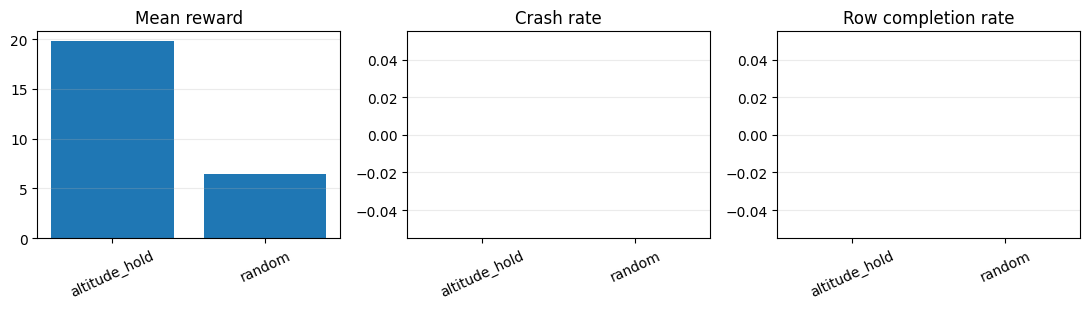

results saved to /Users/nelkitchavezcalona/Projects/UTS/RL/Reinforcement Learning - AT3/agroflight-rl/results/a2c_25399217.json


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col, title in zip(axes, ["mean_reward", "crash_rate", "finish_rate"],
                          ["Mean reward", "Crash rate", "Row completion rate"]):
    ax.bar(df.index, df[col])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

path = save_results(RESULTS)
print("results saved to", path)
if BACKUP_TO_DRIVE:
    backup_to_drive([RESULTS_DIR, CHECKPOINT_DIR])

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> State the headline result in one sentence: the highest level cleared and the samples it needed. Compare against both baselines and against your success criterion from Section 1. Report what did not work as well as what did.</div>

<a id="discussion"></a>

## 8. Discussion

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> <ul><li>Was training stable across seeds? Show the spread, not just the best run.</li><li>Did the reward behave as intended, or did you see reward hacking (for example hovering in place)? Check the viewer, not only the number.</li><li>Where did the algorithm fail, and is that the algorithm, the reward, or the environment?</li><li>Limits: MuJoCo has no rotor ground effect or canopy turbulence; wind is observable; single environment.</li><li>What would you try next with more time?</li></ul></div>

<a id="contribution"></a>

## 9. Contribution and reproducibility

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> Contribution statement (marks are split by individual contribution). Fill in the table.</div>

| | |
|---|---|
| **My contribution** | *what Panzhao built, ran and wrote* |
| **Shared work with teammates** | *environment rework, evaluation harness, viewer, report sections* |
| **AI assistance used** | *which tool, for what, and what you verified yourself* |

In [12]:
import platform
print("python    :", platform.python_version())
print("torch     :", torch.__version__)
print("numpy     :", np.__version__)
print("gymnasium :", gym.__version__)
print("mujoco    :", mujoco.__version__)
print("git commit:", git_commit())
print("train seed:", EXPERIMENT["train_seed"], "| eval seeds:", EXPERIMENT["eval_seeds"][0], "to", EXPERIMENT["eval_seeds"][-1])
print("notebook wall-clock so far: %.0f s" % (time.time() - NOTEBOOK_T0))

python    : 3.11.4
torch     : 2.11.0
numpy     : 2.4.4
gymnasium : 1.3.0
mujoco    : 3.14.0
git commit: 8ecf9ba
train seed: 0 | eval seeds: 1000 to 1019
notebook wall-clock so far: 10 s


### References

1. Mnih, V. et al. (2016). Asynchronous Methods for Deep Reinforcement Learning. ICML. arXiv:1602.01783.
2. Sutton, R. S., Barto, A. G. (2018). Reinforcement Learning: An Introduction, 2nd ed. MIT Press. (Chapter 13, actor-critic methods)
3. Todorov, E., Erez, T., Tassa, Y. (2012). MuJoCo: A physics engine for model-based control. IROS.
4. Google DeepMind. MuJoCo Menagerie: Skydio X2 model (Apache-2.0). github.com/google-deepmind/mujoco_menagerie.
5. Towers, M. et al. (2024). Gymnasium: A Standard Interface for Reinforcement Learning Environments. arXiv:2407.17032.